# 03 — Results analysis
Builds every table (`results/tables/`) and figure (`results/figures/`) from `results/runs.csv`.
Set `TAGS` to `['prelim']` for tonight's preliminary numbers, `['main']` for the final protocol.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
%matplotlib inline
print("project root:", ROOT)

project root: <repo>


In [2]:
import pandas as pd
from src import analysis, data
pd.set_option("display.width", 220)
TAGS = ["prelim"]
runs = analysis.load_runs(tags=TAGS)
print(len(runs), "runs"); runs.groupby(["model", "features", "protocol", "tag"]).size()

33 runs


model  features  protocol  tag   
m1     logmel    actor     prelim    6
                 random    prelim    1
       mfcc      actor     prelim    6
m2     logmel    actor     prelim    6
                 random    prelim    1
m3     logmel    actor     prelim    6
                 random    prelim    1
m4     wave      actor     prelim    6
dtype: int64

## Main table (mean ± std over folds × seeds, %)

In [3]:
analysis.summary_table(runs, name='results_' + '_'.join(TAGS))

,model,features,protocol,tag,n_runs,folds,seeds,UAR (%),Accuracy (%),Macro-F1 (%),val UAR (%),params,trainable,mean train time (s),mean best epoch
0,M1 BiLSTM+Att,logmel,actor,prelim,6,6,1,54.69 ± 4.83,56.25 ± 5.26,53.77 ± 5.12,58.40 ± 4.19,596232,596232,156.9,39.8
1,M1 BiLSTM+Att,logmel,random,prelim,1,1,1,71.48 ± 0.00,72.08 ± 0.00,71.01 ± 0.00,75.39 ± 0.00,596232,596232,197.7,68.0
2,M1 BiLSTM+Att,mfcc,actor,prelim,6,6,1,51.69 ± 1.69,52.64 ± 2.22,50.86 ± 1.42,57.10 ± 3.27,653576,653576,100.1,23.8
3,M2 CNN-BiLSTM,logmel,actor,prelim,6,6,1,61.13 ± 4.00,62.36 ± 4.27,61.13 ± 3.73,64.91 ± 4.24,1276904,1276904,55.3,41.8
4,M2 CNN-BiLSTM,logmel,random,prelim,1,1,1,68.36 ± 0.00,70.00 ± 0.00,68.29 ± 0.00,78.12 ± 0.00,1276904,1276904,57.6,42.0
5,M3 Transformer,logmel,actor,prelim,6,6,1,53.65 ± 6.14,55.62 ± 6.04,52.27 ± 6.99,57.10 ± 6.85,2423048,2423048,20.0,33.8
6,M3 Transformer,logmel,random,prelim,1,1,1,67.97 ± 0.00,69.17 ± 0.00,67.40 ± 0.00,76.95 ± 0.00,2423048,2423048,33.9,67.0
7,M4 wav2vec2-base,wave,actor,prelim,6,6,1,74.09 ± 4.38,74.65 ± 3.55,73.40 ± 4.13,78.26 ± 5.27,94377864,90177416,322.6,22.5


In [4]:
analysis.per_class_recall_table(runs, name='per_class_recall_' + '_'.join(TAGS))

,model,features,protocol,tag,neutral,calm,happy,sad,angry,fearful,disgust,surprised
0,M1 BiLSTM+Att,logmel,actor,prelim,31.2 ± 17.7,60.4 ± 27.1,53.6 ± 13.3,44.3 ± 10.2,79.7 ± 7.1,45.8 ± 15.1,70.8 ± 13.5,51.6 ± 21.1
1,M1 BiLSTM+Att,logmel,random,prelim,62.5 ± 0.0,84.4 ± 0.0,59.4 ± 0.0,65.6 ± 0.0,90.6 ± 0.0,56.2 ± 0.0,87.5 ± 0.0,65.6 ± 0.0
2,M1 BiLSTM+Att,mfcc,actor,prelim,37.5 ± 18.5,60.4 ± 25.9,51.6 ± 8.3,28.1 ± 12.3,68.8 ± 5.2,41.7 ± 15.3,62.5 ± 16.7,63.0 ± 19.1
3,M2 CNN-BiLSTM,logmel,actor,prelim,42.7 ± 11.5,69.8 ± 16.7,52.1 ± 14.1,44.3 ± 7.2,82.3 ± 9.0,58.3 ± 17.5,66.1 ± 18.7,73.4 ± 12.9
4,M2 CNN-BiLSTM,logmel,random,prelim,43.8 ± 0.0,84.4 ± 0.0,50.0 ± 0.0,59.4 ± 0.0,90.6 ± 0.0,65.6 ± 0.0,84.4 ± 0.0,68.8 ± 0.0
5,M3 Transformer,logmel,actor,prelim,24.0 ± 19.5,78.6 ± 15.5,46.4 ± 23.6,40.6 ± 11.2,69.8 ± 17.3,46.9 ± 15.4,66.7 ± 13.4,56.2 ± 22.7
6,M3 Transformer,logmel,random,prelim,50.0 ± 0.0,84.4 ± 0.0,59.4 ± 0.0,53.1 ± 0.0,90.6 ± 0.0,59.4 ± 0.0,84.4 ± 0.0,62.5 ± 0.0
7,M4 wav2vec2-base,wave,actor,prelim,65.6 ± 20.8,80.7 ± 12.1,66.7 ± 9.4,54.7 ± 20.0,87.0 ± 7.2,62.0 ± 15.4,89.6 ± 10.6,86.5 ± 16.1


## Confusion matrices (pooled over all test predictions)

,group,true,pred,count,rate
0,m1_logmel_actor_prelim,neutral,calm,21,0.218750
1,m1_logmel_actor_prelim,happy,fearful,34,0.177083
2,m1_logmel_actor_prelim,surprised,happy,31,0.161458
3,m1_logmel_actor_prelim,neutral,happy,15,0.156250
4,m1_logmel_actor_prelim,calm,sad,29,0.151042
5,m1_logmel_random_prelim,happy,neutral,6,0.187500
6,m1_logmel_random_prelim,fearful,sad,6,0.187500
7,m1_logmel_random_prelim,surprised,happy,5,0.156250
8,m1_logmel_random_prelim,neutral,calm,2,0.125000
9,m1_logmel_random_prelim,neutral,happy,2,0.125000


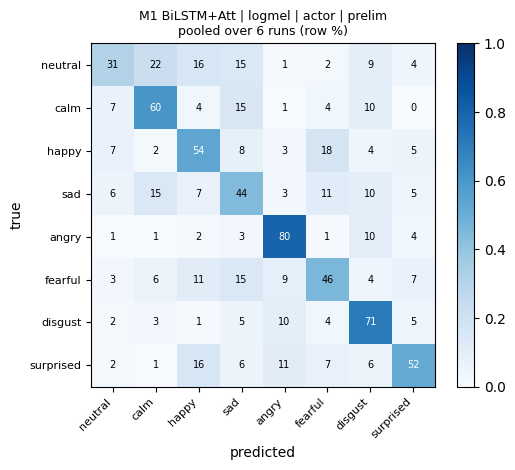

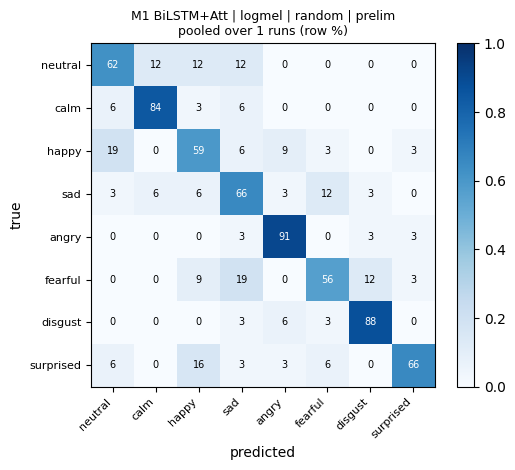

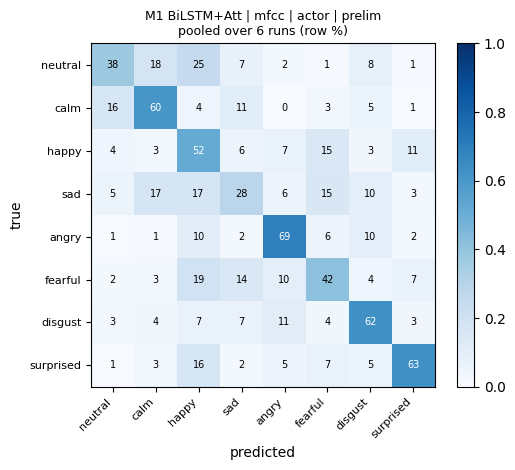

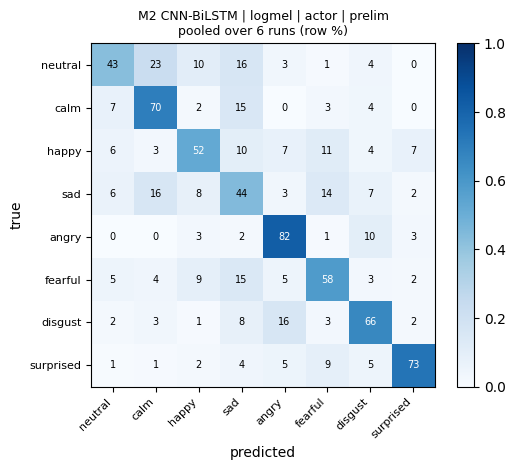

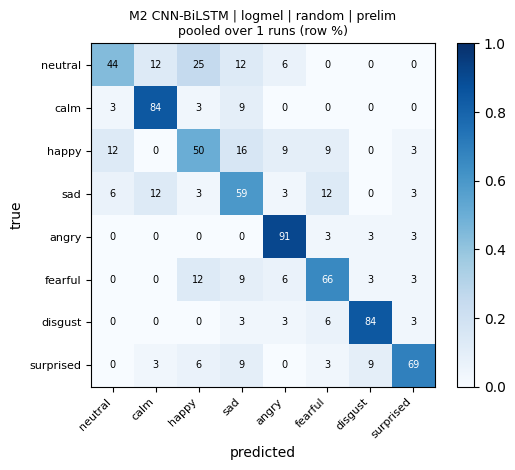

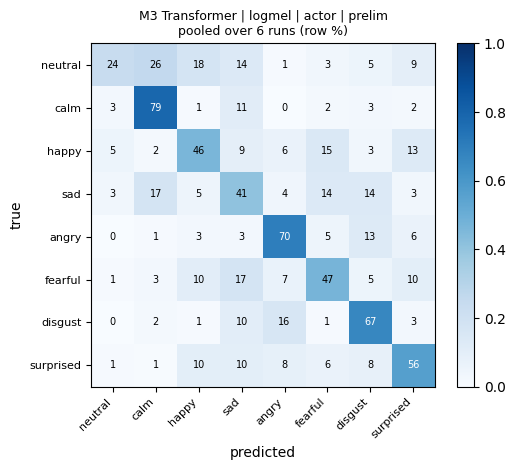

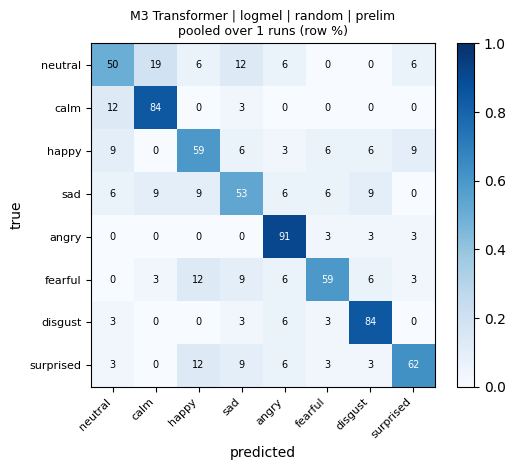

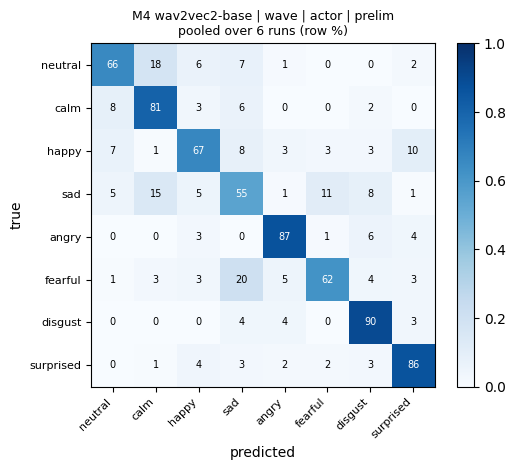

In [5]:
cms = analysis.confusion_figures(runs)
pd.DataFrame([{"group": k, **r} for k, v in cms.items() for r in v["top"]])

## Training / validation curves

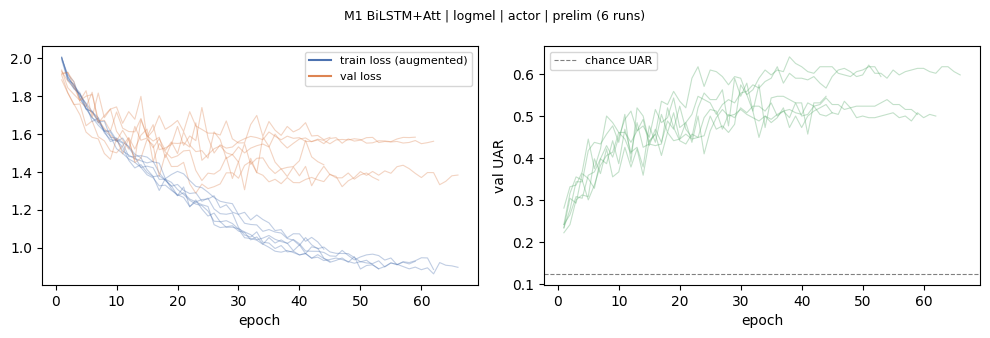

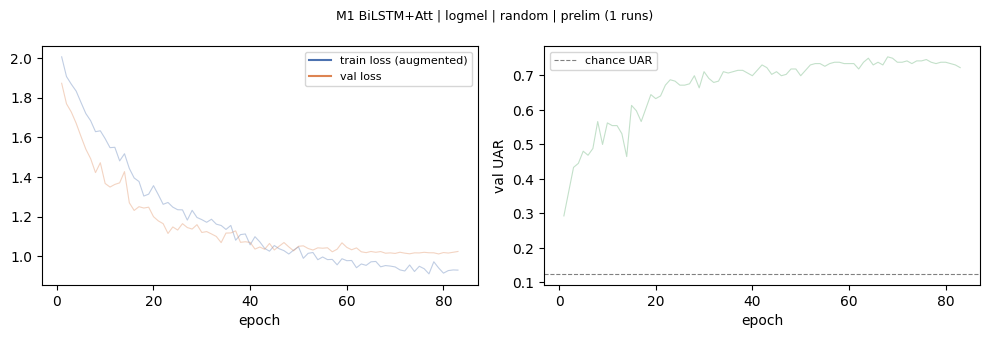

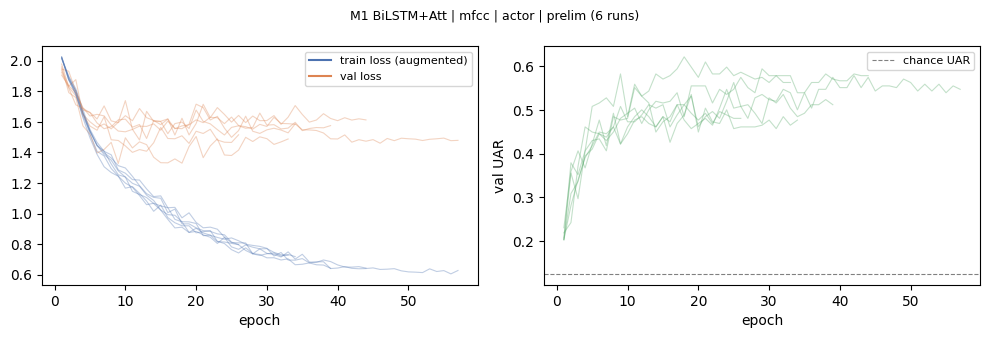

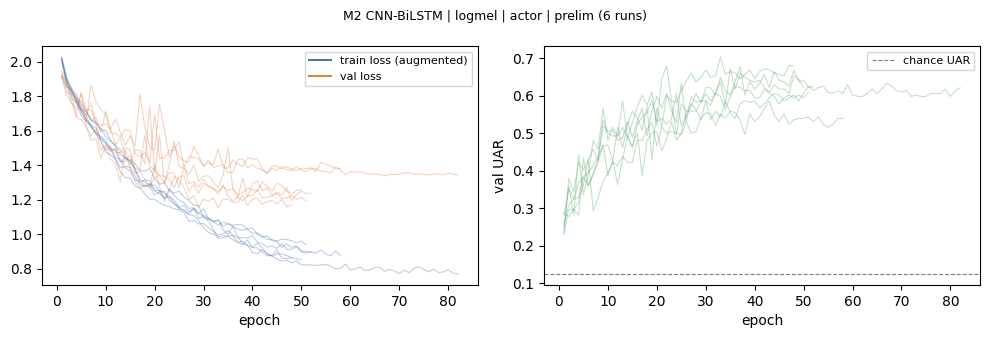

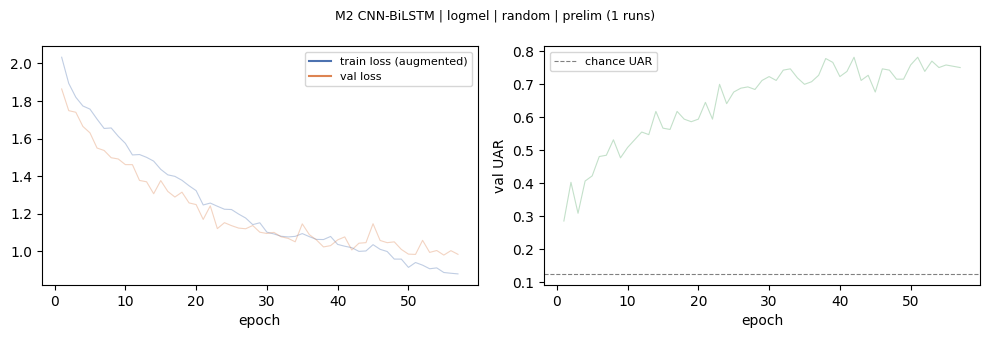

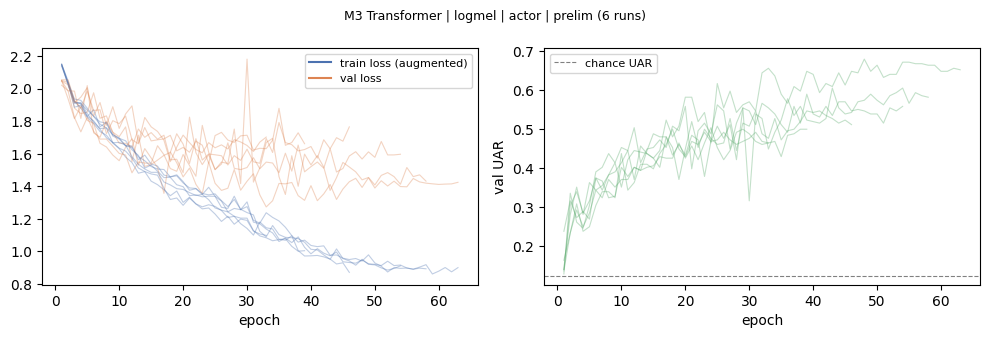

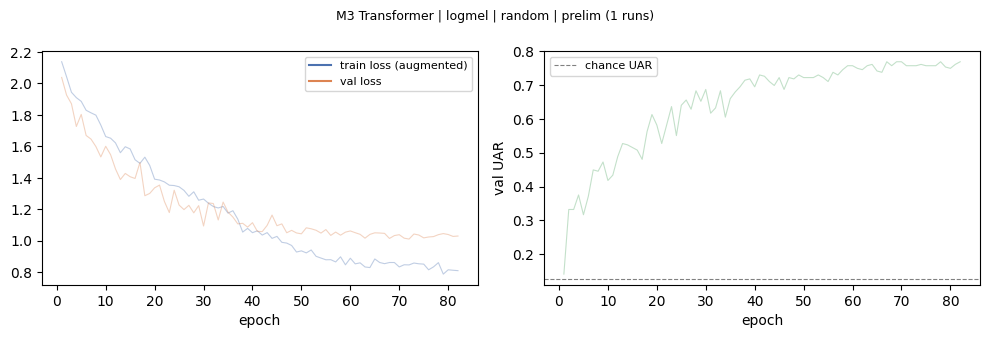

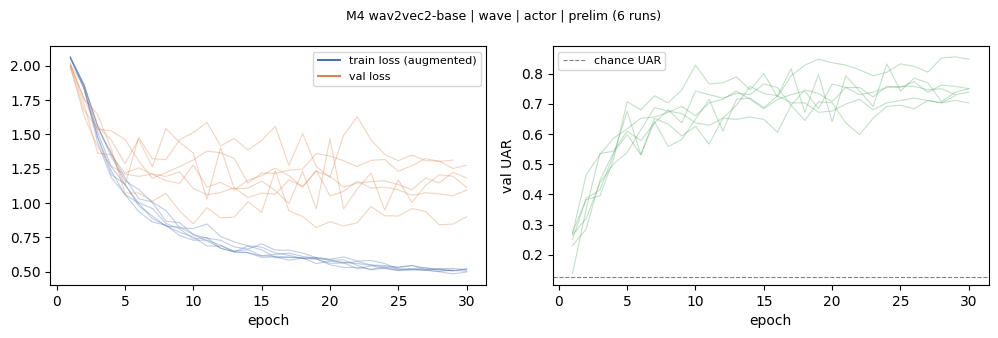

In [6]:
analysis.plot_curves(runs);

## Paired statistical tests (same folds & seeds)

In [7]:
analysis.stats_tests(runs, tag=TAGS[0]) if runs['model'].nunique() > 1 else 'need >= 2 models'

,A,B,n,mean_a,mean_b,mean_diff,std_diff,t,t_p,wilcoxon_W,wilcoxon_p,level
0,m1/logmel,m1/mfcc,6,0.546875,0.516927,0.029948,0.061993,1.183305,0.289878,5.0,0.31250,fold
1,m1/logmel,m1/mfcc,6,0.546875,0.516927,0.029948,0.061993,1.183305,0.289878,5.0,0.31250,run
2,m1/logmel,m2/logmel,6,0.546875,0.611328,-0.064453,0.051453,-3.068385,0.027835,1.0,0.06250,fold
3,m1/logmel,m2/logmel,6,0.546875,0.611328,-0.064453,0.051453,-3.068385,0.027835,1.0,0.06250,run
4,m1/logmel,m3/logmel,6,0.546875,0.536458,0.010417,0.023263,1.096817,0.322714,6.0,0.40625,fold
5,m1/logmel,m3/logmel,6,0.546875,0.536458,0.010417,0.023263,1.096817,0.322714,6.0,0.40625,run
6,m1/logmel,m4/wave,6,0.546875,0.740885,-0.194010,0.046592,-10.199739,0.000155,0.0,0.03125,fold
7,m1/logmel,m4/wave,6,0.546875,0.740885,-0.194010,0.046592,-10.199739,0.000155,0.0,0.03125,run
8,m1/mfcc,m2/logmel,6,0.516927,0.611328,-0.094401,0.050475,-4.581181,0.005941,1.0,0.06250,fold
9,m1/mfcc,m2/logmel,6,0.516927,0.611328,-0.094401,0.050475,-4.581181,0.005941,1.0,0.06250,run


## Feature ablation (M1: log-mel vs MFCC)  and  leakage diagnostic (Q3)

In [8]:
display(analysis.ablation_table(runs, tag=TAGS[0]))
display(analysis.leakage_table(runs, tag=TAGS[0]))

,features,n,UAR (%),Accuracy (%),Macro-F1 (%)
0,logmel,6,54.69 ± 4.83,56.25 ± 5.26,53.77 ± 5.12
1,mfcc,6,51.69 ± 1.69,52.64 ± 2.22,50.86 ± 1.42


,model,actor-wise UAR (%),n_actor,random-split UAR (%),n_random,inflation UAR (points),inflation acc (points)
0,M1 BiLSTM+Att,54.69 ± 4.83,6,71.48 ± 0.00,1,16.80,15.83
1,M2 CNN-BiLSTM,61.13 ± 4.00,6,68.36 ± 0.00,1,7.23,7.64
2,M3 Transformer,53.65 ± 6.14,6,67.97 ± 0.00,1,14.32,13.54


## Hyper-parameter search plots (template section 5.4)

In [9]:
analysis.hparam_plots()

""


## Trivial baselines

In [10]:
analysis.baseline_table(data.load_metadata(), data.load_splits())

test_acc            test_uar           test_macro_f1          
                    mean       std      mean       std          mean       std
baseline                                                                      
majority        0.133333  0.000000  0.125000  0.000000      0.029412  0.000000
prior_random    0.116667  0.012360  0.115234  0.013700      0.114206  0.012924
uniform_random  0.115278  0.014829  0.120443  0.015112      0.114413  0.013904